<a href="https://colab.research.google.com/github/rvinod3426/Financial-Assessment-Classifier-Neural-Network/blob/main/FinalProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Step 1: Importing libraries and the financial survey dataset
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
from google.colab import files
uploaded = files.upload()
filename = list(uploaded.keys())[0]
df_messy = pd.read_csv(filename)
df_messy.head()

Saving NFWBS_PUF_2016_data.csv to NFWBS_PUF_2016_data.csv


,PUF_ID,sample,fpl,SWB_1,SWB_2,SWB_3,FWBscore,FWB1_1,FWB1_2,FWB1_3,...,PPMSACAT,PPREG4,PPREG9,PPT01,PPT25,PPT612,PPT1317,PPT18OV,PCTLT200FPL,finalwt
0,10350,2,3,5,5,6,55,3,3,3,...,1,4,8,0,0,0,0,1,0,0.367292
1,7740,1,3,6,6,6,51,2,2,3,...,1,2,3,0,0,0,0,2,0,1.327561
2,13699,1,3,4,3,4,49,3,3,3,...,1,4,9,0,0,0,1,2,1,0.835156
3,7267,1,3,6,6,6,49,3,3,3,...,1,3,7,0,0,0,0,1,0,1.410871
4,7375,1,3,4,4,4,49,3,3,3,...,1,2,4,0,0,1,0,4,1,4.260668


In [ ]:
# Step 2: Creating a clean and balanced dataset
# 10 columns (X, each feature has certain weightage in determining the y value) and fpl (y value, the model will predict)
selected_columns = ["PPINCIMP", "EMPLOY", "PPEDUC", "PPHHSIZE", "KIDS_NoChildren", "HOUSING", "SAVINGSRANGES", "ENDSMEET", "SNAP", "agecat", "fpl" ]
df_col = df_messy[selected_columns]

# Some responders do not wish to respond and input one of the bad codes instead
bad_codes = [-1,98,99]
SNAP_codes = [-1,98,99,8]

# Calculate medians or modes of each factor to replace the responses with the bad codes with
clean_values = df_col.loc[~df_col["PPINCIMP"].isin(bad_codes), "PPINCIMP"]
PPINCIMP_median = clean_values.median()

clean_values = df_col.loc[~df_col["EMPLOY"].isin(bad_codes), "EMPLOY"]
EMPLOY_mode = clean_values.mode()[0]

clean_values = df_col.loc[~df_col["PPEDUC"].isin(bad_codes), "PPEDUC"]
PPEDUC_median = clean_values.median()

clean_values = df_col.loc[~df_col["PPHHSIZE"].isin(bad_codes), "PPHHSIZE"]
PPHHSIZE_median = clean_values.median()

clean_values = df_col.loc[~df_col["KIDS_NoChildren"].isin(bad_codes), "KIDS_NoChildren"]
KIDS_NoChildren_mode = clean_values.mode()[0]

clean_values = df_col.loc[~df_col["HOUSING"].isin(bad_codes), "HOUSING"]
HOUSING_mode = clean_values.mode()[0]

clean_values = df_col.loc[~df_col["SAVINGSRANGES"].isin(bad_codes), "SAVINGSRANGES"]
SAVINGSRANGES_median = clean_values.median()

clean_values = df_col.loc[~df_col["ENDSMEET"].isin(bad_codes), "ENDSMEET"]
ENDSMEET_median = clean_values.median()

clean_values = df_col.loc[~df_col["SNAP"].isin(SNAP_codes), "SNAP"]
SNAP_mode = clean_values.mode()[0]

clean_values = df_col.loc[~df_col["agecat"].isin(bad_codes), "agecat"]
agecat_median = clean_values.median()

# Creates a balanced dataset with 600 responses from each fpl level (1,2,3)
# This is because there are 1000+ responses with fpl=3 while only ~600 with fpl=1
count = {1: 0, 2: 0, 3: 0}
balanced_rows = []
for index, row in df_col.iterrows():
  cls = row["fpl"]
  if count[cls] < 600:
    balanced_rows.append(row)
    count[cls] +=1
df_balanced = pd.DataFrame(balanced_rows).reset_index(drop=True)

# Replaces any bad codes in the balanced dataset with the median or mode of that column
fill_values = {
  "PPINCIMP" : PPINCIMP_median, "EMPLOY" : EMPLOY_mode,
  "PPEDUC" : PPEDUC_median, "PPHHSIZE" : PPHHSIZE_median, "KIDS_NoChildren" :
  KIDS_NoChildren_mode, "HOUSING" : HOUSING_mode, "SAVINGSRANGES" : SAVINGSRANGES_median,
  "ENDSMEET" : ENDSMEET_median, "SNAP" : SNAP_mode, "agecat" : agecat_median}

for col in fill_values:
    df_balanced[col] = df_balanced[col].replace({code: fill_values[col] for code in bad_codes})

# SNAP has an extra bad code (8) which needs to be removed
df_balanced["SNAP"] = df_balanced["SNAP"].replace({8: SNAP_mode})

# Replaces 1,2,3 into 0,1,2 because CrossEntropyLoss reads from 0
df_balanced["fpl"] = df_balanced["fpl"].map({1: 0, 2: 1, 3: 2})

# Splits the balanced dataset into X and y
X = df_balanced.drop(columns=["fpl"])
y = df_balanced["fpl"]

print(df_balanced.head())


   PPINCIMP  EMPLOY  PPEDUC  PPHHSIZE  KIDS_NoChildren  HOUSING  \
0         7       8       4         1                1        1   
1         6       2       2         2                1        1   
2         6       2       3         3                0        1   
3         8       2       2         1                1        1   
4         7       2       2         5                1        2   

   SAVINGSRANGES  ENDSMEET  SNAP  agecat  fpl  
0              6         2     0       8    2  
1              2         2     0       3    2  
2              4         1     0       3    2  
3              5         1     0       3    2  
4              5         2     0       2    2  


In [ ]:
# Step 3: Converting and scaling data for testing and training
# Splits the data into 75% for training and 25% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Scales the training and testing data by calculating mean and stdev
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Converts into PyTorch Sensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.long).to(device)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.long).to(device)

# stores number of features (10) by calling number of columns
input_size = X_train_tensor.shape[1]


print("Training examples:", X_train.shape[0])
print("Testing examples:", X_test.shape[0])
print()
print("y_train class counts:")
print(pd.Series(y_train).value_counts().sort_index())
print()
print("y_test class counts:")
print(pd.Series(y_test).value_counts().sort_index())
print("\nTraining examples:", X_train_tensor.shape[0])
print("Testing examples:", X_test_tensor.shape[0])
print("Input features:", input_size)

Training examples: 1350
Testing examples: 450

y_train class counts:
fpl
0    450
1    450
2    450
Name: count, dtype: int64

y_test class counts:
fpl
0    150
1    150
2    150
Name: count, dtype: int64

Training examples: 1350
Testing examples: 450
Input features: 10


In [ ]:
# Step 4: Neural Network Architecture (2 hidden layers)

torch.manual_seed(42)
np.random.seed(42)
# Creates Python class for model, inherits from PyTorch base model
class FinancialAssessmentModel(nn.Module):


    def __init__ (self, input_size):

        super().__init__()

        # Creates two hidden layers
        # First Layer: 64 neurons, Second Layer: 32 neurons,
        # Output: 3 possible outputs
        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64 , 32),
            nn.ReLU(),
            nn.Linear(32,3)
        )

    def forward(self, x):
      return self.network(x)


model = FinancialAssessmentModel(input_size)
model = model.to(device)
print(model)



FinancialAssessmentModel(
  (network): Sequential(
    (0): Linear(in_features=10, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=3, bias=True)
  )
)


In [ ]:
# Step 5: Loss, Optimization, Loop training

criterion = nn.CrossEntropyLoss()

# Learning rate of 0.001 provided best results
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 400
loss_track = []
for epoch in range(epochs):
  model.train()
  optimizer.zero_grad()
  outputs = model(X_train_tensor)
  loss = criterion(outputs, y_train_tensor)
  loss.backward()
  optimizer.step()
  loss_track.append(loss.item())
print("Final training loss", round(loss_track[-1],4))

Final training loss 0.0972


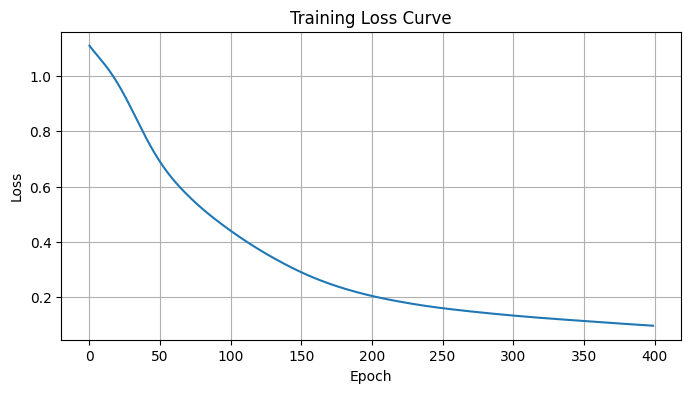

Test Accuracy: 0.9133


In [ ]:
# Step 6: Evaluation
plt.figure(figsize=(8, 4))
plt.plot(loss_track)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss Curve")
plt.grid(True)
plt.show()


model.eval()
with torch.no_grad():
    test_outputs = model(X_test_tensor)
    _, predicted = torch.max(test_outputs, 1)

print("Test Accuracy:", round(accuracy_score(y_test_tensor.cpu(), predicted.cpu()),4))



In [ ]:
# Step 7: Prediction Function

label_names = {
    0: "Below Poverty Line",
    1: "Low Income",
    2: "Above Poverty Line"
}

def predict_poverty(profile_dict):
    profile_df = pd.DataFrame([profile_dict])
    profile_scaled = scaler.transform(profile_df)
    profile_tensor = torch.tensor(profile_scaled, dtype=torch.float32).to(device)

    model.eval()
    with torch.no_grad():
        output = model(profile_tensor)
        probabilities = torch.softmax(output, dim=1)
        confidence, predicted = torch.max(probabilities, 1)

    predicted_label = label_names[predicted.item()]
    print("Predicted Poverty Level:", predicted_label)
    print(f"Confidence: {confidence.item():.2%}")

    # Plotting the probabilities
    prob_values = probabilities.cpu().squeeze().numpy()
    labels = [label_names[i] for i in range(len(label_names))]

    plt.figure(figsize=(8, 5))
    plt.bar(labels, prob_values, color=['skyblue', 'lightcoral', 'lightgreen'])
    plt.ylabel('Probability')
    plt.title('Predicted Probability Distribution for Poverty Levels')
    plt.ylim(0, 1)
    plt.show()

Predicted Poverty Level: Above Poverty Line
Confidence: 99.99%


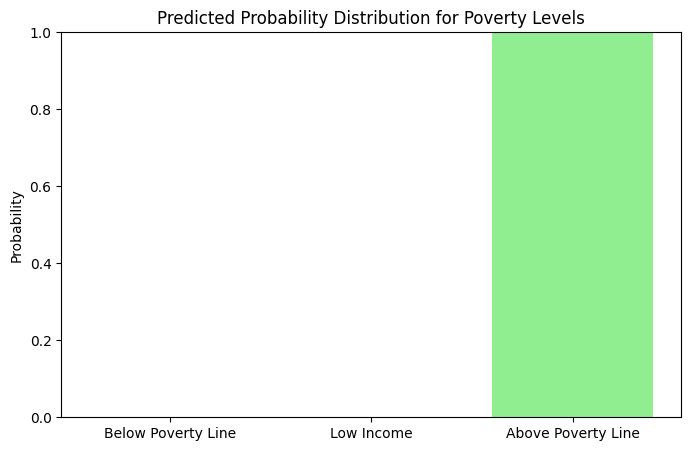

Predicted Poverty Level: Below Poverty Line
Confidence: 99.95%


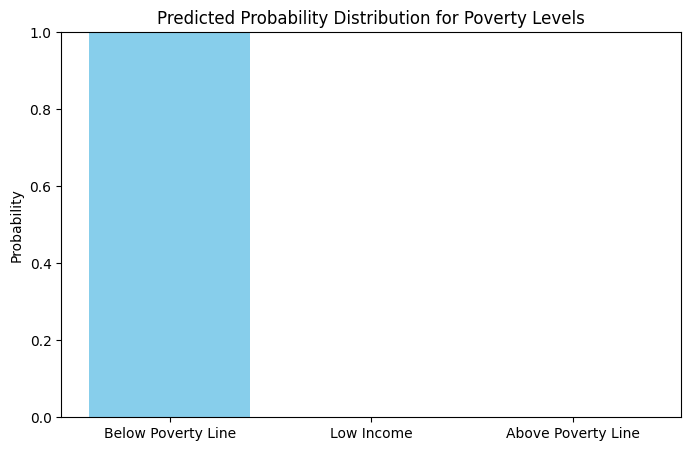

Predicted Poverty Level: Low Income
Confidence: 96.47%


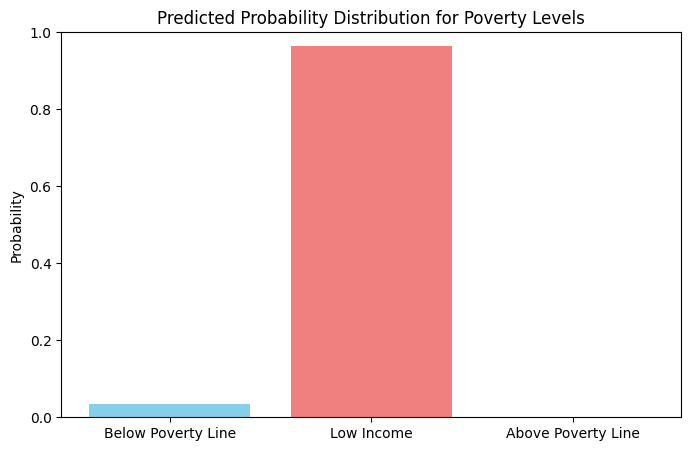

In [ ]:
# Step 8: Custom Predictions for each class

above_poverty_profile = {
    "PPINCIMP": 6,
    "EMPLOY": 2,
    "PPEDUC": 4,
    "PPHHSIZE": 3,
    "KIDS_NoChildren": 2,
    "HOUSING": 1,
    "SAVINGSRANGES": 4,
    "ENDSMEET": 3,
    "SNAP": 0,
    "agecat": 4
}


below_poverty_profile = {
    "PPINCIMP": 1,
    "EMPLOY": 6,
    "PPEDUC": 1,
    "PPHHSIZE": 4,
    "KIDS_NoChildren": 1,
    "HOUSING": 2,
    "SAVINGSRANGES": 1,
    "ENDSMEET": 1,
    "SNAP": 1,
    "agecat": 3
}

low_income_profile = {
    "PPINCIMP": 2,
    "EMPLOY": 3,
    "PPEDUC": 2,
    "PPHHSIZE": 3,
    "KIDS_NoChildren": 1,
    "HOUSING": 2,
    "SAVINGSRANGES": 2,
    "ENDSMEET": 2,
    "SNAP": 0,
    "agecat": 5
}

predict_poverty(above_poverty_profile)
predict_poverty(below_poverty_profile)
predict_poverty(low_income_profile)

## Features Selected from Data:
####1. Household Income (PPINCIMP)


*   Contains values from 1-9
*   Each number correspond to an income, ranging from less than \$20,000 to over \$150,000


####2. Employment Status (EMPLOY)


*   Contains values from 1-8
*   Values represent several employment options, including self-employed, work full-time, full-time student, unemployed, retired, etc.


####3. Level of Education (PPEDUC)


*   Contains values from 1-5
*   Values range from less than high school to graduate/professional degree


####4. Household Size (PPHHSIZE)


*   Contains values from 1-5
*   All the numbers correspond to the actual number of people in the household from 1-4, but if there are 5\+ in the household, the value in the table is 5


####5. Financial Suppport of Children (KIDS_NoChildren)


*   Contains values from 0-1
*   1 represents a participant that does not support any children, and 0 is a respondent that does financially support children


####6. Housing Situation (HOUSING)


*   Contains values from 1-3
*   Values represent the options of owning a home, renting a home, and neither renting nor owning a home


####7. Amount in Savings (SAVINGSRANGES)


*   Contains values from 2-7
*   Values represent anywhere from \$1-99 in savings all the way to \$75,000 or more


####8. Expenses and Bills Covered Every Month (ENDSMEET)


*   Contains values from 1-3
*   Each number represents a range from not at all difficult (1) to very difficult (3)


####9. Receives Food Benefits (SNAP)


*   Contains values from 0-1
*   A value of 1 means that the participant received benefits from either the Food Stamp Program or the Supplemental Nutrition Assistance Program (SNAP), while a value of 0 means that they did not


####10. Age Range of Participant (agecat)


*   Contains values from 1-8
*   Values correspond to ages ranging from 18-75+

